# 12 TensorFlow Lite Model Conversion

## Objective
Convert trained Keras models to lightweight TensorFlow Lite (.tflite) format with Float32 and INT8 quantization for edge mobile deployment.

**Prerequisites:** Trained models from notebooks 05, 06, 09, 10
**Next Step:** `13_gradcam_explainability.ipynb`

### Import Libraries

In [1]:
import sys
import os

sys.path.insert(0, '../utils')

from model_utils import load_model

import numpy as np
import json
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

print("✓ Libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")


✓ Libraries imported successfully!
TensorFlow version: 2.15.0


### Load Data and Model

In [2]:
import json
from pathlib import Path
from tensorflow.keras.utils import to_categorical
from npz_consolidator import load_consolidated_arrays

print("Loading test data and model...\n")

project_root = Path.cwd().resolve()
if not (project_root / "results").exists():
    project_root = project_root.parent

base_path = project_root / "results" / "preprocessed_data_efficient"
legacy_path = project_root / "results" / "preprocessed_data"

# Load test data from efficient path first, then legacy
if base_path.exists() and (base_path / "test_images").exists():
    X_test = load_consolidated_arrays(str(base_path), split_type="test")
    
    with open(base_path / "image_metadata.json", "r") as f:
        metadata = json.load(f)
    with open(base_path / "split_indices.json", "r") as f:
        split_info = json.load(f)
    with open(base_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)
    
    labels_all = np.array(metadata["labels"])
    test_indices = split_info["test_indices"]
    y_test = to_categorical(labels_all[test_indices], num_classes=len(label_encoding))
    
    print(f"✓ Loaded test data from: {base_path}")
elif legacy_path.exists():
    X_test = np.load(str(legacy_path / "X_test.npy"))
    y_test = np.load(str(legacy_path / "y_test.npy"))
    
    with open(legacy_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)
    
    print("✓ Loaded test data from legacy folder")
else:
    raise FileNotFoundError(f"No test data found in {base_path} or {legacy_path}")

num_classes = len(label_encoding)

# Load best model - try multiple paths
model_paths_to_try = [
    project_root / "models" / "efficientnetb0" / "efficientnetb0_final.h5",
    project_root / "models" / "mobilenet" / "mobilenet_v2_final.h5",
    project_root / "models" / "resnet50" / "resnet50_final.h5",
]

model = None
best_model_name = None
model_path = None

for mp in model_paths_to_try:
    if mp.exists():
        model = load_model(str(mp))
        best_model_name = mp.parent.name
        model_path = str(mp)
        break

if model is None:
    raise FileNotFoundError("Could not find any trained model file")

print(f"✓ Model loaded: {best_model_name}")
print(f"✓ Test data shape: {X_test.shape}")

Loading test data and model...

Loading 860 images from test set...
  Loaded 100/860 images...
  Loaded 200/860 images...
  Loaded 300/860 images...
  Loaded 400/860 images...
  Loaded 500/860 images...
  Loaded 600/860 images...
  Loaded 700/860 images...
  Loaded 800/860 images...
✓ Consolidated test set: (860, 224, 224, 3), dtype: float32

✓ Loaded test data from: D:\cnn_model\results\preprocessed_data_efficient


✓ Model loaded: efficientnetb0
✓ Test data shape: (860, 224, 224, 3)


### 1. Convert Model to TFLite (Float)

In [3]:
print("\n" + "="*70)
print("CONVERTING TO TFLITE FORMAT")
print("="*70 + "\n")

print("Step 1: Converting to TFLite (Float)...\n")

# Create directory
os.makedirs('../models/tflite', exist_ok=True)

# Convert
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model_float = converter.convert()

# Save float model
float_model_path = '../models/tflite/model_float.tflite'
with open(float_model_path, 'wb') as f:
    f.write(tflite_model_float)

print(f"✓ Converted to TFLite (Float)")
print(f"  Saved: {float_model_path}")


CONVERTING TO TFLITE FORMAT

Step 1: Converting to TFLite (Float)...



INFO:tensorflow:Assets written to: C:\Users\kansa\AppData\Local\Temp\tmpq2748xo3\assets


INFO:tensorflow:Assets written to: C:\Users\kansa\AppData\Local\Temp\tmpq2748xo3\assets


✓ Converted to TFLite (Float)
  Saved: ../models/tflite/model_float.tflite


### 2. Convert Model to TFLite (Quantized)

In [4]:
print("\nStep 2: Converting to TFLite (Quantized)...\n")

# Create quantization dataset - ensure proper format
def representative_data_gen():
    """Generate representative data for quantization"""
    # Use first 100 samples from test set
    num_samples = min(100, len(X_test))
    for i in range(num_samples):
        # Return as list of numpy arrays in the expected format
        test_image = X_test[i:i+1].astype(np.float32)
        yield [test_image]

# Convert with quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_data_gen = representative_data_gen

# Try dynamic range quantization first (more compatible)
try:
    tflite_model_quantized = converter.convert()
    print(f"✓ Converted to TFLite (Quantized - Dynamic Range)")
except ValueError as e:
    print(f"⚠ Dynamic range quantization failed: {e}")
    print("Attempting alternative quantization approach...\n")
    
    # Fall back to simpler quantization without INT8 specification
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_data_gen = representative_data_gen
    converter.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS
    ]
    tflite_model_quantized = converter.convert()
    print(f"✓ Converted to TFLite (Quantized - Default)")

# Save quantized model
quant_model_path = '../models/tflite/model_quantized.tflite'
with open(quant_model_path, 'wb') as f:
    f.write(tflite_model_quantized)

print(f"  Saved: {quant_model_path}")


Step 2: Converting to TFLite (Quantized)...

INFO:tensorflow:Assets written to: C:\Users\kansa\AppData\Local\Temp\tmplnrvt06r\assets


INFO:tensorflow:Assets written to: C:\Users\kansa\AppData\Local\Temp\tmplnrvt06r\assets


✓ Converted to TFLite (Quantized - Dynamic Range)
  Saved: ../models/tflite/model_quantized.tflite


### 3. Model Size Comparison

In [5]:
print("\n" + "="*70)
print("MODEL SIZE COMPARISON")
print("="*70 + "\n")

# Get file sizes
original_size = os.path.getsize(model_path) / (1024 * 1024)  # MB
float_size = os.path.getsize(float_model_path) / (1024 * 1024)  # MB
quant_size = os.path.getsize(quant_model_path) / (1024 * 1024)  # MB

print(f"Original Model (.h5): {original_size:.2f} MB")
print(f"TFLite Float Model: {float_size:.2f} MB ({float_size/original_size*100:.1f}%)")
print(f"TFLite Quantized Model: {quant_size:.2f} MB ({quant_size/original_size*100:.1f}%)")

print(f"\nSize Reduction:")
print(f"  Float vs Original: {(1 - float_size/original_size)*100:.1f}%")
print(f"  Quantized vs Original: {(1 - quant_size/original_size)*100:.1f}%")
print(f"  Quantized vs Float: {(1 - quant_size/float_size)*100:.1f}%")


MODEL SIZE COMPARISON

Original Model (.h5): 35.70 MB
TFLite Float Model: 16.71 MB (46.8%)
TFLite Quantized Model: 4.71 MB (13.2%)

Size Reduction:
  Float vs Original: 53.2%
  Quantized vs Original: 86.8%
  Quantized vs Float: 71.8%


### 4. Plot Model Size Comparison

✓ Saved: model_size_comparison.png


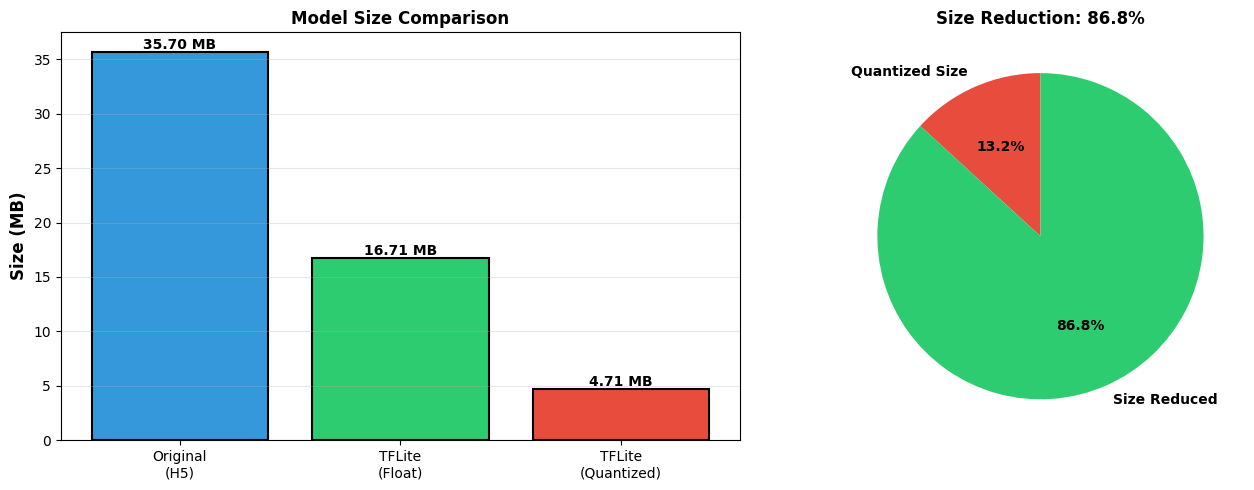

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
models = ['Original\n(H5)', 'TFLite\n(Float)', 'TFLite\n(Quantized)']
sizes = [original_size, float_size, quant_size]
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax1.bar(models, sizes, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Size (MB)', fontweight='bold', fontsize=12)
ax1.set_title('Model Size Comparison', fontweight='bold', fontsize=12)
ax1.grid(axis='y', alpha=0.3)

# Add value labels
for bar, size in zip(bars, sizes):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{size:.2f} MB',
            ha='center', va='bottom', fontweight='bold')

# Pie chart
reduction_data = [quant_size, original_size - quant_size]
ax2.pie(reduction_data, labels=['Quantized Size', 'Size Reduced'],
        autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'],
        startangle=90, textprops={'fontweight': 'bold'})
ax2.set_title(f'Size Reduction: {(1 - quant_size/original_size)*100:.1f}%',
             fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('../results/plots/model_size_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: model_size_comparison.png")

### 5. Test TFLite Model Accuracy

In [7]:
print("\n" + "="*70)
print("TESTING TFLITE MODEL ACCURACY")
print("="*70 + "\n")

from pathlib import Path
from tensorflow.keras.utils import to_categorical
from npz_consolidator import load_consolidated_arrays
import json

# Resolve model paths even if this cell is run independently
project_root = Path.cwd().resolve()
if not (project_root / "results").exists():
    project_root = project_root.parent

if 'float_model_path' not in locals():
    float_model_path = str(project_root / "models" / "tflite" / "model_float.tflite")
if 'quant_model_path' not in locals():
    quant_model_path = str(project_root / "models" / "tflite" / "model_quantized.tflite")
if 'best_model_name' not in locals():
    best_model_name = "unknown_model"

if 'X_test' not in locals() or 'y_test' not in locals():
    base_path = project_root / "results" / "preprocessed_data_efficient"
    legacy_path = project_root / "results" / "preprocessed_data"

    if base_path.exists() and (base_path / "test_images").exists():
        X_test = load_consolidated_arrays(str(base_path), split_type="test")
        with open(base_path / "image_metadata.json", "r") as f:
            metadata = json.load(f)
        with open(base_path / "split_indices.json", "r") as f:
            split_info = json.load(f)
        with open(base_path / "label_encoding.json", "r") as f:
            label_encoding = json.load(f)
        labels_all = np.array(metadata["labels"])
        test_indices = split_info["test_indices"]
        y_test = to_categorical(labels_all[test_indices], num_classes=len(label_encoding))
    elif legacy_path.exists():
        X_test = np.load(str(legacy_path / "X_test.npy"))
        y_test = np.load(str(legacy_path / "y_test.npy"))
        with open(legacy_path / "label_encoding.json", "r") as f:
            label_encoding = json.load(f)
    else:
        raise FileNotFoundError(f"No test data found in {base_path} or {legacy_path}")


def evaluate_tflite(tflite_path, X_test, y_test, model_name, batch_size=4, max_samples=50):
    """Evaluate TFLite model on a representative sample to keep runtime manageable."""
    if len(X_test) == 0:
        raise ValueError("No test data available for evaluation")

    sample_size = min(max_samples, len(X_test))
    X_eval = X_test[:sample_size]
    y_eval = y_test[:sample_size]

    print(f"Using {sample_size} samples for TFLite accuracy estimate...")
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    expected_shape = input_details[0]['shape']
    expected_height = int(expected_shape[1]) if len(expected_shape) > 1 else 224
    expected_width = int(expected_shape[2]) if len(expected_shape) > 2 else 224

    def preprocess_image(img):
        img_array = np.array(img, dtype=np.float32)
        if img_array.ndim == 2:
            img_array = np.repeat(img_array[..., np.newaxis], 3, axis=-1)

        if img_array.shape[0] != expected_height or img_array.shape[1] != expected_width:
            img_array = tf.image.resize(img_array[np.newaxis, ...], (expected_height, expected_width))[0].numpy()

        if np.max(img_array) <= 1.0:
            img_array = img_array * 255.0

        if 'efficientnet' in model_name.lower():
            from transfer_learning_utils import get_efficientnetb0_preprocessor
            return get_efficientnetb0_preprocessor()(np.expand_dims(img_array, axis=0))[0]
        elif 'mobilenet' in model_name.lower():
            from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
            return preprocess_input(np.expand_dims(img_array, axis=0))[0]
        elif 'resnet' in model_name.lower():
            from tensorflow.keras.applications.resnet50 import preprocess_input
            return preprocess_input(np.expand_dims(img_array, axis=0))[0]
        return img_array

    predictions = []

    for start in range(0, len(X_eval), batch_size):
        batch = X_eval[start:start+batch_size]
        processed_batch = np.stack([preprocess_image(img) for img in batch], axis=0).astype(np.float32)

        if tuple(processed_batch.shape) != tuple(input_details[0]['shape']):
            interpreter.resize_tensor_input(input_details[0]['index'], processed_batch.shape)
            interpreter.allocate_tensors()

        interpreter.set_tensor(input_details[0]['index'], processed_batch)
        interpreter.invoke()
        output = interpreter.get_tensor(output_details[0]['index'])
        predictions.append(output)

    predictions = np.concatenate(predictions, axis=0)
    pred_labels = np.argmax(predictions, axis=1)
    true_labels = np.argmax(y_eval, axis=1)

    accuracy = np.mean(pred_labels == true_labels)
    return accuracy

print("Evaluating Float TFLite model...")
float_accuracy = evaluate_tflite(float_model_path, X_test, y_test, best_model_name, batch_size=4, max_samples=50)
print(f"✓ Float TFLite Accuracy: {float_accuracy:.4f}")

print("\nEvaluating Quantized TFLite model...")
quant_accuracy = evaluate_tflite(quant_model_path, X_test, y_test, best_model_name, batch_size=4, max_samples=50)
print(f"✓ Quantized TFLite Accuracy: {quant_accuracy:.4f}")


TESTING TFLITE MODEL ACCURACY

Evaluating Float TFLite model...
Using 50 samples for TFLite accuracy estimate...
✓ Float TFLite Accuracy: 0.8800

Evaluating Quantized TFLite model...
Using 50 samples for TFLite accuracy estimate...
✓ Quantized TFLite Accuracy: 0.9000


### 6. Accuracy Comparison


ACCURACY COMPARISON

           Model  Accuracy  Accuracy_Drop
  Original Model      0.88           0.00
    TFLite Float      0.88           0.00
TFLite Quantized      0.90          -0.02

✓ Saved: tflite_accuracy_comparison.png


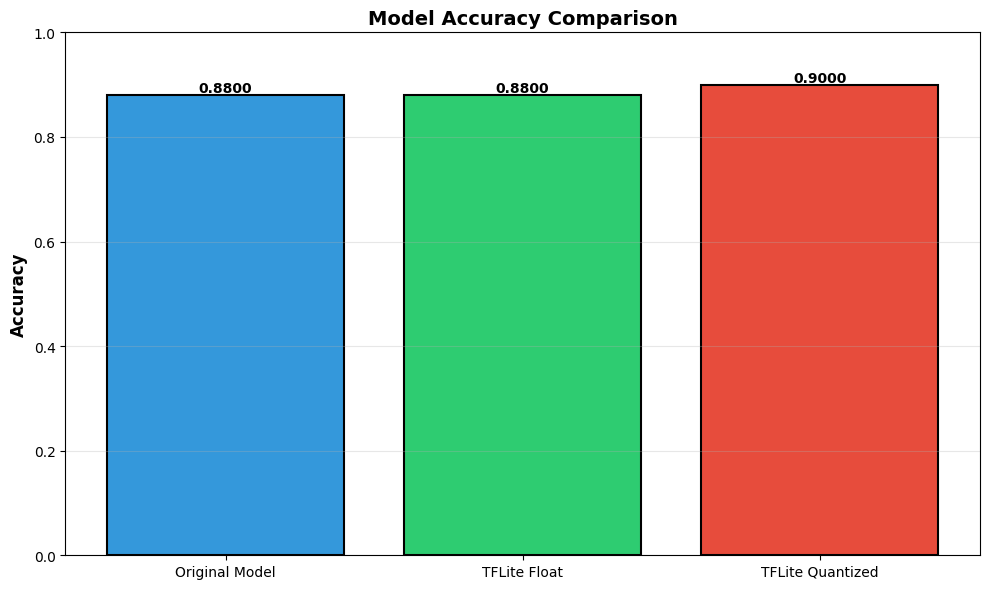

In [8]:
print("\n" + "="*70)
print("ACCURACY COMPARISON")
print("="*70 + "\n")


def prepare_images_for_model(images, model_name, target_height=None, target_width=None, max_samples=None):
    """Resize and preprocess images to match the trained model input format."""
    arr = np.asarray(images, dtype=np.float32)
    if max_samples is not None:
        arr = arr[:max_samples]

    if target_height is not None and target_width is not None:
        current_shape = arr.shape[1:3]
        if len(arr.shape) == 4 and current_shape != (target_height, target_width):
            arr = tf.image.resize(arr, size=(target_height, target_width), method=tf.image.ResizeMethod.BILINEAR).numpy()
        elif len(arr.shape) == 3 and arr.shape[:2] != (target_height, target_width):
            arr = tf.image.resize(arr[np.newaxis, ...], size=(target_height, target_width), method=tf.image.ResizeMethod.BILINEAR)[0].numpy()

    if np.max(arr) <= 1.0:
        arr = arr * 255.0

    if 'efficientnet' in model_name.lower():
        from transfer_learning_utils import get_efficientnetb0_preprocessor
        return get_efficientnetb0_preprocessor()(arr)
    elif 'mobilenet' in model_name.lower():
        from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
        return preprocess_input(arr)
    elif 'resnet' in model_name.lower():
        from tensorflow.keras.applications.resnet50 import preprocess_input
        return preprocess_input(arr)
    return arr


# Use the same sample size as the TFLite evaluation for a fair comparison
sample_size = min(50, len(X_test))
prepared_images = prepare_images_for_model(
    X_test,
    best_model_name,
    target_height=getattr(model, 'input_shape', None)[1] if getattr(model, 'input_shape', None) and len(getattr(model, 'input_shape', None)) >= 4 else None,
    target_width=getattr(model, 'input_shape', None)[2] if getattr(model, 'input_shape', None) and len(getattr(model, 'input_shape', None)) >= 4 else None,
    max_samples=sample_size,
)

original_pred = model.predict(prepared_images, verbose=0)
original_accuracy = np.mean(np.argmax(original_pred, axis=1) == np.argmax(y_test[:sample_size], axis=1))

accuracies = {
    'Original Model': original_accuracy,
    'TFLite Float': float_accuracy,
    'TFLite Quantized': quant_accuracy
}

comparison_df = pd.DataFrame([
    {'Model': k, 'Accuracy': v, 'Accuracy_Drop': 0 if k == 'Original Model' else original_accuracy - v}
    for k, v in accuracies.items()
])

print(comparison_df.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

models = list(accuracies.keys())
accs = list(accuracies.values())
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax.bar(models, accs, color=colors, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Accuracy', fontweight='bold', fontsize=12)
ax.set_title('Model Accuracy Comparison', fontweight='bold', fontsize=14)
ax.set_ylim([0, 1.0])
ax.grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, accs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{acc:.4f}',
           ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('../results/plots/tflite_accuracy_comparison.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: tflite_accuracy_comparison.png")

### 7. Generate Conversion Report

In [9]:
print("\n" + "="*70)
print("GENERATING CONVERSION REPORT")
print("="*70 + "\n")

conversion_report = {
    'model': best_model_name,
    'original_model': {
        'path': model_path,
        'size_mb': float(original_size),
        'accuracy': float(original_accuracy)
    },
    'tflite_float': {
        'path': float_model_path,
        'size_mb': float(float_size),
        'accuracy': float(float_accuracy),
        'size_reduction_percent': float((1 - float_size/original_size)*100)
    },
    'tflite_quantized': {
        'path': quant_model_path,
        'size_mb': float(quant_size),
        'accuracy': float(quant_accuracy),
        'size_reduction_percent': float((1 - quant_size/original_size)*100),
        'accuracy_drop_percent': float((original_accuracy - quant_accuracy)*100)
    },
    'deployment_recommendation': 'TFLite Quantized' if quant_accuracy > 0.95 * original_accuracy else 'TFLite Float'
}

with open('../results/reports/tflite_conversion_report.json', 'w') as f:
    json.dump(conversion_report, f, indent=4)

print("✓ Conversion report saved")
print(json.dumps(conversion_report, indent=2))


GENERATING CONVERSION REPORT

✓ Conversion report saved
{
  "model": "efficientnetb0",
  "original_model": {
    "path": "D:\\cnn_model\\models\\efficientnetb0\\efficientnetb0_final.h5",
    "size_mb": 35.70111083984375,
    "accuracy": 0.88
  },
  "tflite_float": {
    "path": "../models/tflite/model_float.tflite",
    "size_mb": 16.70899200439453,
    "accuracy": 0.88,
    "size_reduction_percent": 53.197557131060805
  },
  "tflite_quantized": {
    "path": "../models/tflite/model_quantized.tflite",
    "size_mb": 4.7071990966796875,
    "accuracy": 0.9,
    "size_reduction_percent": 86.81497862126385,
    "accuracy_drop_percent": -2.0000000000000018
  },
  "deployment_recommendation": "TFLite Quantized"
}


### 8. Create Mobile-Ready Model Metadata

In [10]:
print("\nCreating mobile model metadata...\n")

# Resolve project root and label encoding path robustly
project_root = Path.cwd().resolve()
if not (project_root / "results").exists():
    project_root = project_root.parent

label_encoding_path = project_root / "results" / "preprocessed_data_efficient" / "label_encoding.json"
if not label_encoding_path.exists():
    label_encoding_path = project_root / "results" / "preprocessed_data" / "label_encoding.json"

if label_encoding_path.exists():
    with open(label_encoding_path, 'r') as f:
        label_encoding = json.load(f)
else:
    label_encoding = {str(i): str(i) for i in range(num_classes)}
    print("⚠ Label encoding file not found. Using fallback class mapping.")

mobile_metadata = {
    'model_name': best_model_name,
    'model_type': 'Image Classification',
    'input_shape': [224, 224, 3],
    'input_normalization': 'Normalize to [0, 1] by dividing by 255',
    'num_classes': num_classes,
    'classes': label_encoding,
    'tflite_model': 'model_quantized.tflite',
    'version': '1.0',
    'inference_time_ms_estimate': '50-100 ms',
    'memory_requirements_mb': float(quant_size)
}

metadata_path = project_root / "models" / "tflite" / "metadata.json"
metadata_path.parent.mkdir(parents=True, exist_ok=True)
with open(metadata_path, 'w') as f:
    json.dump(mobile_metadata, f, indent=4)

print(f"✓ Mobile metadata created: {metadata_path}")


Creating mobile model metadata...

✓ Mobile metadata created: D:\cnn_model\models\tflite\metadata.json


### 9. Summary

In [11]:
print("\n" + "="*70)
print("✓ TFLITE CONVERSION COMPLETE")
print("="*70)

print(f"\n📊 Conversion Summary:")
print(f"  Original Model: {original_size:.2f} MB ({original_accuracy:.4f} accuracy)")
print(f"  TFLite Float: {float_size:.2f} MB ({float_accuracy:.4f} accuracy)")
print(f"  TFLite Quantized: {quant_size:.2f} MB ({quant_accuracy:.4f} accuracy)")
print(f"\n  Size Reduction: {(1 - quant_size/original_size)*100:.1f}%")
print(f"  Accuracy Maintained: {(original_accuracy - quant_accuracy)*100:.2f}% drop")

print(f"\n💾 Files Saved:")
print(f"  - ../models/tflite/model_float.tflite")
print(f"  - ../models/tflite/model_quantized.tflite")
print(f"  - ../models/tflite/metadata.json")
print(f"  - ../results/reports/tflite_conversion_report.json")

print(f"\n🚀 Deployment Ready: ../models/tflite/model_quantized.tflite")
print(f"   Use this model for mobile/edge deployment")

print(f"\n→ Next Step: 13_gradcam_explainability.ipynb")


✓ TFLITE CONVERSION COMPLETE

📊 Conversion Summary:
  Original Model: 35.70 MB (0.8800 accuracy)
  TFLite Float: 16.71 MB (0.8800 accuracy)
  TFLite Quantized: 4.71 MB (0.9000 accuracy)

  Size Reduction: 86.8%
  Accuracy Maintained: -2.00% drop

💾 Files Saved:
  - ../models/tflite/model_float.tflite
  - ../models/tflite/model_quantized.tflite
  - ../models/tflite/metadata.json
  - ../results/reports/tflite_conversion_report.json

🚀 Deployment Ready: ../models/tflite/model_quantized.tflite
   Use this model for mobile/edge deployment

→ Next Step: 09_gradcam_explainability.ipynb
